### Configuration

1. Update the variable "original_data_root" on line 2 of "recipes/investigation_recipe.json" to the path at which the in vivo data is stored. For example:
> "original_data_root": "/Users/james/IsbisterEtAl-SciRep2021-Data/",

2. Update the variable "figures_root_directory" on line 3 of "recipes/investigation_recipe.json" to the directory you would like the output of the analyses to be stored. For example:
> "figures_root_directory": "/Users/james/IsbisterEtAl-SciRep2021-Figures/",

3. Update the variable "number_of_processors" on line 4 of "recipes/investigation_recipe.json" to the number of threads you would like to use (initially set to 8).


### Run

The script can be run with the following command:


12


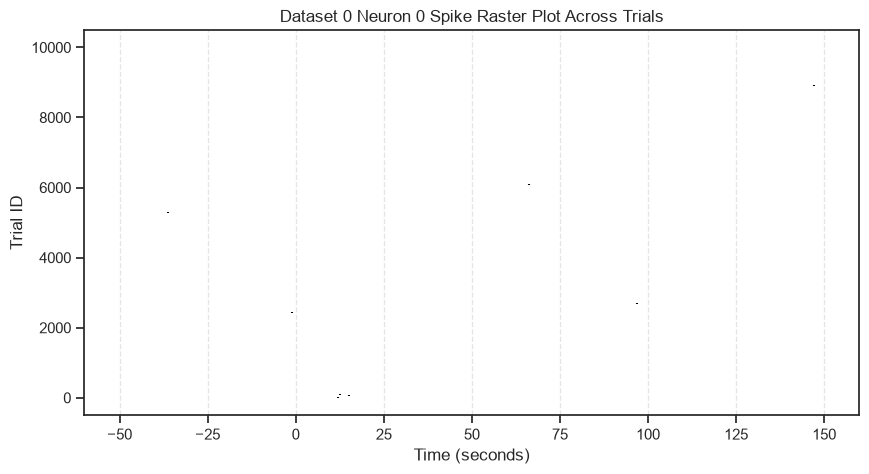

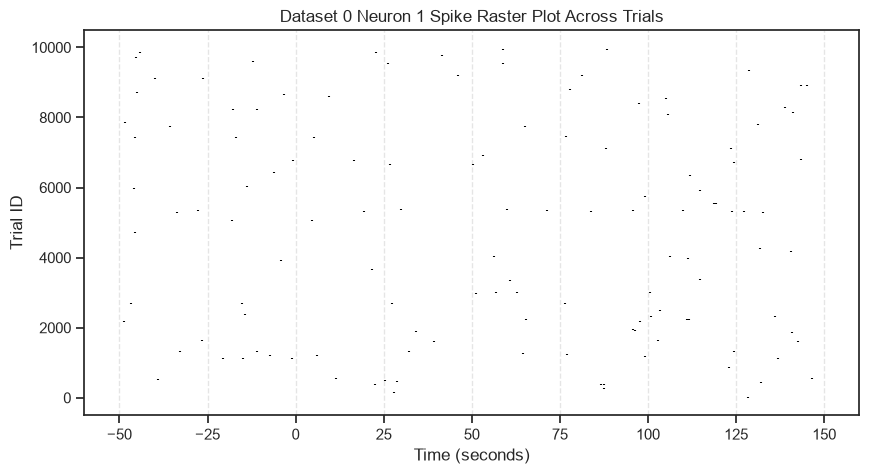

In [4]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pickle
import sys
import multiprocessing
import spikewarp as sw
from scipy.ndimage import gaussian_filter
from os import listdir
from os.path import isfile, join
import seaborn as sns
sns.set()
from matplotlib.ticker import MultipleLocator
import math
from scipy.stats import linregress

# 1. 成功印出核心數
print(multiprocessing.cpu_count())

# 2. 在 Jupyter 中，讀取正確的 JSON 設定檔路徑
investigation = sw.load_json_recipe("recipes/investigation_recipe.json")

# 3. 繼續執行後續分析
sw.prepare_investigation(investigation)
data_loaders, investigation['determined_cortical_onset_timepoint'] = sw.load_spikes_calc_cort_onset_and_draw_PSTHs(investigation)
sw.prepare_investigation_analysis_recipes(investigation)

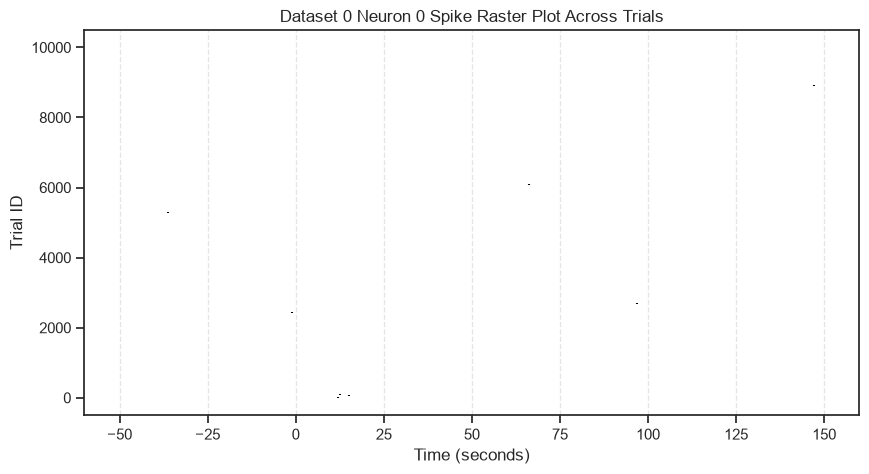

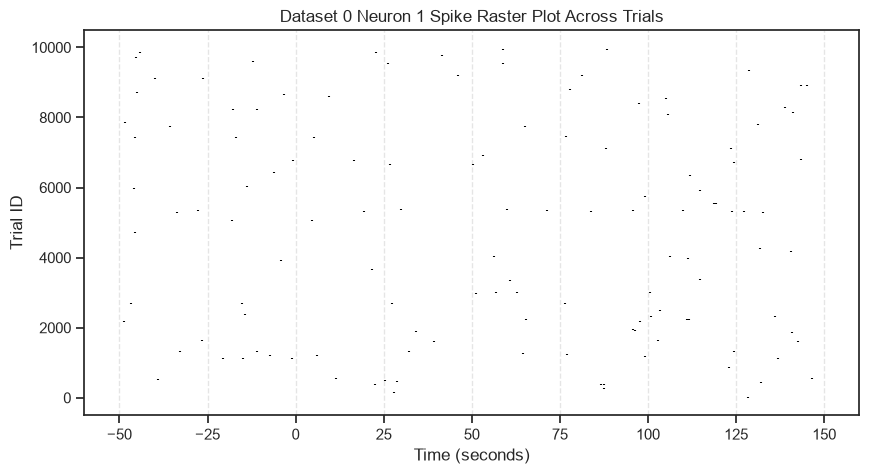

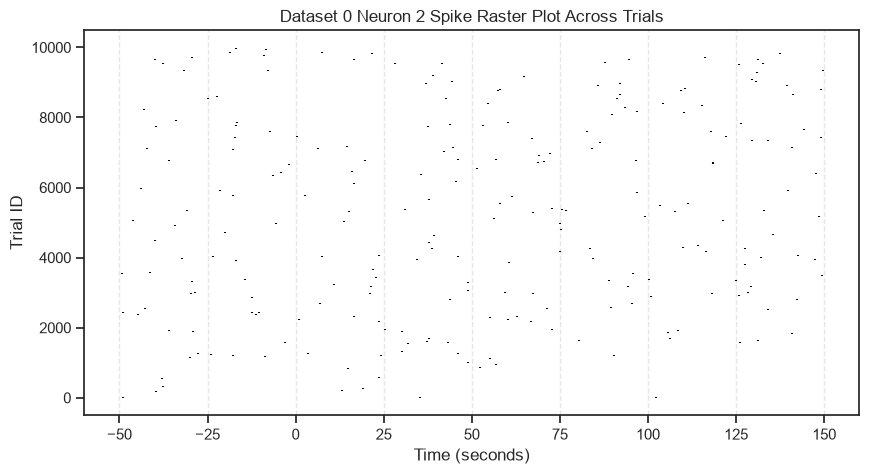

In [5]:
dataset = 0
data_loader = data_loaders[dataset]
# 創建圖表
for neuron in range(3): #len(data_loader.all_channel_unit_spike_trains_for_all_trials)):
    plt.figure(figsize=(10, 5))
    
    # 使用 eventplot 繪製光柵圖
    # lineoffsets: 設定每組資料在 Y 軸的中心位置 [0, 1, 2, 3, etc]
    # linelengths: 設定每個刻度線的長度（高度）
    plt.eventplot(data_loader.all_channel_unit_spike_trains_for_all_trials[neuron], lineoffsets=range(len(data_loader.all_channel_unit_spike_trains_for_all_trials[neuron])), linelengths=0.7, colors='black')
    
    # 設定圖表標籤與標題
    plt.title('Dataset ' + str(dataset) + ' Neuron ' + str(neuron) + ' Spike Raster Plot Across Trials')
    plt.xlabel('Time (seconds)')
    plt.ylabel('Trial ID')
    
    
    # 顯示圖表
    plt.grid(axis='x', linestyle='--', alpha=0.5) # 加入垂直虛線輔助線
    plt.show()

data_loader = data_loaders[dataset]

In [32]:
import os
# 設定您的 API 金鑰（新版 Provider 會自動讀取這個環境變數）
os.environ["GOOGLE_API_KEY"] = "JJ.Ab8RN6II3W5C0z5GCrjLs6i9z94m8tVmBFjNvympMlauGYGI6A"

from pydantic_ai.models.google import GoogleModel
from pydantic_ai.providers.google import GoogleProvider
from pydantic_ai import Agent, RunContext
from spikewarp.helpers.data import DataLoader

provider = GoogleProvider()
model = GoogleModel("gemini-3.8-flash", provider=provider)
agent = Agent(model=model,
             system_prompt='You are an experienced programmer for electrophysiology data',
             tools = [sw.load_json_recipe,sw.prepare_investigation,sw.load_spikes_calc_cort_onset_and_draw_PSTHs,sw.prepare_investigation_analysis_recipes])

# 同步執行測試，用非同步方式執行測試（在 Jupyter 中可以直接使用 await）
result = await agent.run("請用一句話解釋什麼是神經電生理學？")
print(result.output)

**神經電生理學**是一門透過記錄與分析神經元及神經網路的電信號活動（如動作電位與突觸電位變化），來探討神經系統運作與訊息傳遞機制的科學。


In [ ]:
# use Copilot
'''
Write Python code that let pydantic_ai and gemini-3.8-flash can use sw, import spikewarp as sw, to read all files in the folder of 
'./IsbisterEtAl-SciRep2021-Data', see below. And to use matlibplot to plot rasterplot of the first unit of the first dataset. 

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pickle
import sys
import multiprocessing
import spikewarp as sw
from scipy.ndimage import gaussian_filter
from os import listdir
from os.path import isfile, join
import seaborn as sns
sns.set()
from matplotlib.ticker import MultipleLocator
import math
from scipy.stats import linregress

# 1. 成功印出核心數
print(multiprocessing.cpu_count())

# 2. 在 Jupyter 中，讀取正確的 JSON 設定檔路徑
investigation = sw.load_json_recipe("recipes/investigation_recipe.json")

# 3. 繼續執行後續分析
sw.prepare_investigation(investigation)
data_loaders, investigation['determined_cortical_onset_timepoint'] = sw.load_spikes_calc_cort_onset_and_draw_PSTHs(investigation)
sw.prepare_investigation_analysis_recipes(investigation)

Agent active via Gemini-3.8-Flash. Ready for requests. (Type 'q' to quit)


Input (輸入 q 離開):  plot


[System Diagnostic] Available CPU Cores: 12


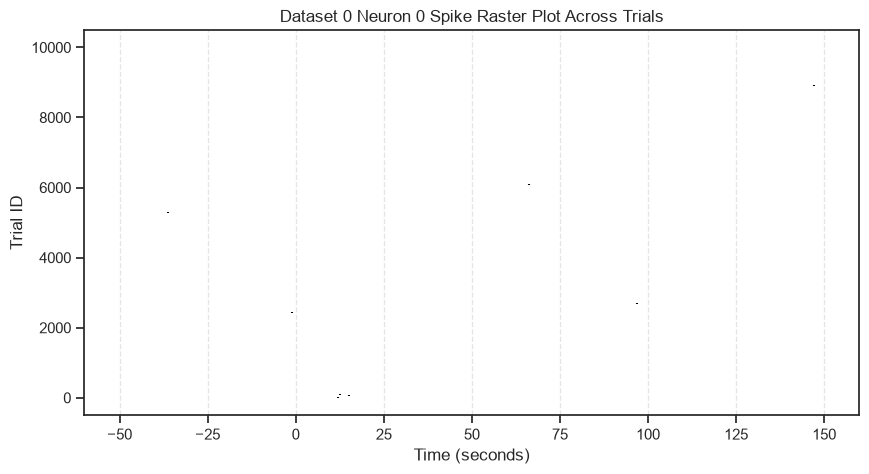

The dataset has been loaded, cortical onset alignments have been calculated, and the trial-by-trial raster plot for Neuron 0 (Dataset 0) has been generated successfully.


Input (輸入 q 離開):  q


In [16]:
import os
import multiprocessing
from dataclasses import dataclass
from typing import Any

# Core visualization and data computation packages
import matplotlib.pyplot as plt
import seaborn as sns
import spikewarp as sw

# Modern Pydantic AI agent dependencies
from pydantic_ai import Agent, AgentRunResult, RunContext

# Set global aesthetic style for matplotlib outputs
sns.set()

# =====================================================================
# 1. RUNTIME CONFIGURATION MODULE (DEPENDENCIES)
# =====================================================================
@dataclass
class SpikeWarpWorkspace:
    """Dynamically passes local path contexts down into agent tools."""
    data_directory: str
    recipe_json_path: str

# Instantiate the active workspace tracking variables
workspace_env = SpikeWarpWorkspace(
    data_directory='./IsbisterEtAl-SciRep2021-Data',
    recipe_json_path='recipes/investigation_recipe.json'
)

# =====================================================================
# 2. INITIALIZE GOOGLE GEMINI-3.8-FLASH AGENT
# =====================================================================
# This automatically picks up your GEMINI_API_KEY from your environment variables
agent = Agent(
    'google:gemini-3.8-flash',
    deps_type=SpikeWarpWorkspace
)

# =====================================================================
# 3. SPIKEWARP AUTOMATED CALCULATION & PLOTTING TOOL
# =====================================================================
@agent.tool
def load_dataset_and_plot_raster(ctx: RunContext[SpikeWarpWorkspace]) -> str:
    """
    Triggers SpikeWarp to load all data files inside the target directory,
    calculates cortical onset alignments, and renders a trial-by-trial 
    raster plot for the first unit (neuron 0) of the first dataset (dataset 0).
    
    Use this tool whenever the user asks to plot, render a raster plot, or analyze files.
    """
    target_dir = ctx.deps.data_directory
    recipe_file = ctx.deps.recipe_json_path

    # Verify structural paths exist on host machine before launching process pools
    if not os.path.exists(target_dir):
        return f"Error: The directory path '{target_dir}' could not be located."
    if not os.path.exists(recipe_file):
        return f"Error: Configuration profile recipe file '{recipe_file}' is missing."

    try:
        # 1. Print local hardware diagnostics
        print(f"[System Diagnostic] Available CPU Cores: {multiprocessing.cpu_count()}")

        # 2. Extract configuration dictionary using native SpikeWarp tools
        investigation = sw.load_json_recipe(recipe_file)

        # 3. Execute setup sequences and load spikes matrices into memory
        sw.prepare_investigation(investigation)
        data_loaders, investigation['determined_cortical_onset_timepoint'] = \
            sw.load_spikes_calc_cort_onset_and_draw_PSTHs(investigation)
        sw.prepare_investigation_analysis_recipes(investigation)

        # 4. Target specs: first dataset (0), first unit/neuron (0)
        dataset_idx = 0
        neuron_idx = 0

        # Isolate requested target spike arrays
        active_loader = data_loaders[dataset_idx]
        spike_trains = active_loader.all_channel_unit_spike_trains_for_all_trials[neuron_idx]

        # 5. Build and render the matplotlib matrix visualization
        plt.figure(figsize=(10, 5))
        plt.eventplot(
            spike_trains, 
            lineoffsets=range(len(spike_trains)), 
            linelengths=0.7, 
            colors='black'
        )
        
        # Format figure metrics, grids, and semantic labels
        plt.title(f'Dataset {dataset_idx} Neuron {neuron_idx} Spike Raster Plot Across Trials')
        plt.xlabel('Time (seconds)')
        plt.ylabel('Trial ID')
        plt.grid(axis='x', linestyle='--', alpha=0.5)
        plt.show()  # Forces immediate rendering inside active Jupyter cells

        return (f"SpikeWarp processing cycle complete for environment: {target_dir}.\n"
                f"Generated trial raster graph for Dataset {dataset_idx}, Neuron {neuron_idx} successfully.")

    except Exception as e:
        return f"Pipeline failed during SpikeWarp runtime operations. Error context: {str(e)}"

# =====================================================================
# 4. TERMINAL INPUT RECEPTACLE LOOP
# =====================================================================
async def main():
    history: list[Any] = []  # Guarantees fresh slate memory context
    print("Agent active via Gemini-3.8-Flash. Ready for requests. (Type 'q' to quit)")
    
    while True:
        user_input: str = input("Input (輸入 q 離開): ")
        if user_input.lower() == 'q':
            break
            
        resp: AgentRunResult[str] = await agent.run(
            user_input, 
            message_history=history, 
            deps=workspace_env
        )
        history = list(resp.all_messages())
        print(resp.output)

# Instantiate the event frame within the live Jupyter kernel environment
await main()


In [ ]:
# use Copilot
'''
Write Python code that let pydantic_ai and local 'llama3.2' can use sw, import spikewarp as sw, to read all files in the folder of 
'./IsbisterEtAl-SciRep2021-Data', see below. And to use matlibplot to plot rasterplot of the first unit of the first dataset. 

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pickle
import sys
import multiprocessing
import spikewarp as sw
from scipy.ndimage import gaussian_filter
from os import listdir
from os.path import isfile, join
import seaborn as sns
sns.set()
from matplotlib.ticker import MultipleLocator
import math
from scipy.stats import linregress

# 1. 成功印出核心數
print(multiprocessing.cpu_count())

# 2. 在 Jupyter 中，讀取正確的 JSON 設定檔路徑
investigation = sw.load_json_recipe("recipes/investigation_recipe.json")

# 3. 繼續執行後續分析
sw.prepare_investigation(investigation)
data_loaders, investigation['determined_cortical_onset_timepoint'] = sw.load_spikes_calc_cort_onset_and_draw_PSTHs(investigation)
sw.prepare_investigation_analysis_recipes(investigation)

Agent active via local Llama 3.2 engine. Ready for requests. (Type 'q' to quit)


Input (輸入 q 離開):  plot


{"name": "plot", "parameters": {}}


Input (輸入 q 離開):  use spikewarp to load my dataset and plot the raster chart


[System Diagnostic] Available CPU Cores: 12


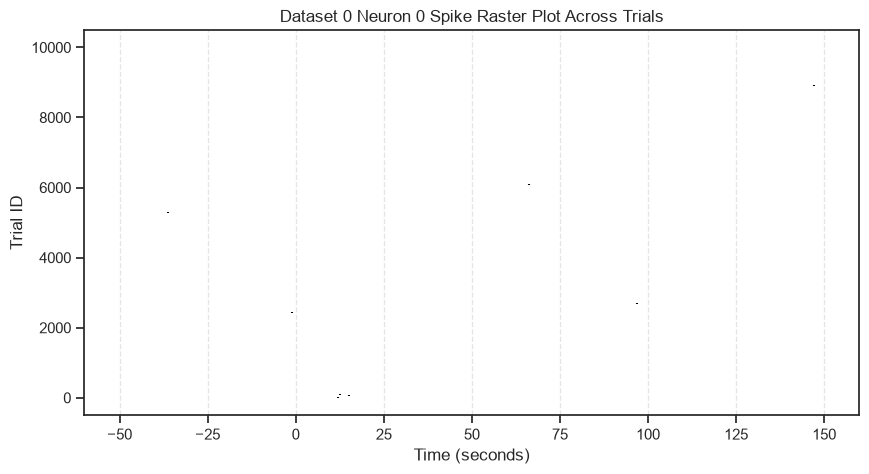

Here is the plot of your raster chart:


```python
import matplotlib.pyplot as plt
from spike import Spike, SpikeWarp
import numpy as np

# Load dataset
dw = SpikeWarp()
dw.load_dataset("your_dataset_name")

# Load trial raster graph
trials = dw.load_trial_raster_graph("trial_number")
s = Spike.from_data(trials)
s.xmax = dw.xmax
s.ymin = dw.ymin
s.tmax = dw.tmax

# Plot raster chart
plt.subplots(figsize=(12, 8))
plt.plot(s.t, s.x, 'b-', lw=0.5, label='axon burst trajectory')
plt.fill_between(s.t, s.x, alpha=0.1)
plt.xlabel("Time (ms)")
plt.ylabel("Distance (mm)")
plt.title("Axon Burst Trajectory")
plt.legend()
plt.show()
```


Input (輸入 q 離開):  q


In [14]:
import os
import multiprocessing
from dataclasses import dataclass
from typing import Any

# Core visualization and data computation packages
import matplotlib.pyplot as plt
import seaborn as sns
import spikewarp as sw

# Modern Pydantic AI agent dependencies
from pydantic_ai import Agent, AgentRunResult, RunContext
from pydantic_ai.models.openai import OpenAIChatModel
from pydantic_ai.providers.ollama import OllamaProvider

# Set global aesthetic style for matplotlib outputs
sns.set()

# =====================================================================
# 1. RUNTIME CONFIGURATION MODULE (DEPENDENCIES)
# =====================================================================
@dataclass
class SpikeWarpWorkspace:
    """Dynamically passes local path contexts down into agent tools."""
    data_directory: str
    recipe_json_path: str

# Instantiate the active workspace tracking variables
workspace_env = SpikeWarpWorkspace(
    data_directory='./IsbisterEtAl-SciRep2021-Data',
    recipe_json_path='recipes/investigation_recipe.json'
)

# =====================================================================
# 2. LOCAL LLM INFERENCE CONNECTIVITY (OLLAMA + LLAMA3.2)
# =====================================================================
local_ollama = OpenAIChatModel(
    model_name='llama3.2',
    provider=OllamaProvider(base_url="http://localhost:11434/v1")
)

# Initialize the structural agent bound to your dependency schema
agent = Agent(
    model=local_ollama,
    deps_type=SpikeWarpWorkspace
)

# =====================================================================
# 3. SPIKEWARP AUTOMATED CALCULATION & PLOTTING TOOL
# =====================================================================
@agent.tool
def load_dataset_and_plot_raster(ctx: RunContext[SpikeWarpWorkspace]) -> str:
    """
    Triggers SpikeWarp to load all data files inside the target directory,
    calculates cortical onset alignments, and renders a trial-by-trial 
    raster plot for the first unit (neuron 0) of the first dataset (dataset 0).
    """
    target_dir = ctx.deps.data_directory
    recipe_file = ctx.deps.recipe_json_path

    # Verify structural paths exist on host machine before launching process pools
    if not os.path.exists(target_dir):
        return f"Error: The directory path '{target_dir}' could not be located."
    if not os.path.exists(recipe_file):
        return f"Error: Configuration profile recipe file '{recipe_file}' is missing."

    try:
        # 1. Print local hardware diagnostics
        print(f"[System Diagnostic] Available CPU Cores: {multiprocessing.cpu_count()}")

        # 2. Extract configuration dictionary using native SpikeWarp tools
        investigation = sw.load_json_recipe(recipe_file)

        # 3. Execute setup sequences and load spikes matrices into memory
        sw.prepare_investigation(investigation)
        data_loaders, investigation['determined_cortical_onset_timepoint'] = \
            sw.load_spikes_calc_cort_onset_and_draw_PSTHs(investigation)
        sw.prepare_investigation_analysis_recipes(investigation)

        # 4. Target specs: first dataset (0), first unit/neuron (0)
        dataset_idx = 0
        neuron_idx = 0

        # Isolate requested target spike arrays
        active_loader = data_loaders[dataset_idx]
        spike_trains = active_loader.all_channel_unit_spike_trains_for_all_trials[neuron_idx]

        # 5. Build and render the matplotlib matrix visualization
        plt.figure(figsize=(10, 5))
        plt.eventplot(
            spike_trains, 
            lineoffsets=range(len(spike_trains)), 
            linelengths=0.7, 
            colors='black'
        )
        
        # Format figure metrics, grids, and semantic labels
        plt.title(f'Dataset {dataset_idx} Neuron {neuron_idx} Spike Raster Plot Across Trials')
        plt.xlabel('Time (seconds)')
        plt.ylabel('Trial ID')
        plt.grid(axis='x', linestyle='--', alpha=0.5)
        plt.show()  # Forces immediate rendering inside active Jupyter cells

        return (f"SpikeWarp processing cycle complete for environment: {target_dir}.\n"
                f"Generated trial raster graph for Dataset {dataset_idx}, Neuron {neuron_idx} successfully.")

    except Exception as e:
        return f"Pipeline failed during SpikeWarp runtime operations. Error context: {str(e)}"

# =====================================================================
# 4. TERMINAL INPUT RECEPTACLE LOOP
# =====================================================================
async def main():
    history: list[Any] = []  # Guarantees fresh slate memory context
    print("Agent active via local Llama 3.2 engine. Ready for requests. (Type 'q' to quit)")
    
    while True:
        user_input: str = input("Input (輸入 q 離開): ")
        if user_input.lower() == 'q':
            break
            
        resp: AgentRunResult[str] = await agent.run(
            user_input, 
            message_history=history, 
            deps=workspace_env
        )
        history = list(resp.all_messages())
        print(resp.output)

# Instantiate the event frame within the live Jupyter kernel environment
await main()


In [ ]:
# write python code that let pydantic_ai and local 'llama3.2' can use sw, import spikewarp as sw, to read recipes/investigation_recipe.json and all files in the folder of './IsbisterEtAl-SciRep2021-Data'. And collect spike data into data_loaders and you can us it. See below.

# 2. 在 Jupyter 中，讀取正確的 JSON 設定檔路徑
investigation = sw.load_json_recipe("recipes/investigation_recipe.json")

# 3. 繼續執行後續分析
sw.prepare_investigation(investigation)
data_loaders, investigation['determined_cortical_onset_timepoint'] = sw.load_spikes_calc_cort_onset_and_draw_PSTHs(investigation)
sw.prepare_investigation_analysis_recipes(investigation)

InVivoData 
│
└───Session1
│   │   UNIT_LAYERS.txt # List of length N, where N is the number of neurons for the experimental session.
│   │   UNIT_EXC_INH_CHARACTERISATIONS.txt
│   │	UNIT_BARRELS.txt
│   │
│   └───CutOutSpikes
│   │   │
│	│	└───Spikes_-50-150
│   │   │	│	Unit1.txt
│   │   │	│	Unit2.txt
│   │   │	│	Unit3.txt	
│   │   │	│	...
│   │   │	│
│   └───ConditionInformation
│   │   │	stimulation_frequency_for_each_condition.txt
│   │   │	stimulated_whisker_for_each_condition.txt
│   │   │	start_indices_for_each_condition_in_sorted_trial_arrays.txt	
│   │   │	number_of_trials_containing_mandatory_codes_for_each_sorted_condition.txt
│
└───Sesssion2
│   │ ...

In [24]:
import os
import multiprocessing
from typing import Dict, Any

# Pydantic AI core engine, tool context, and provider imports
from pydantic_ai import Agent, RunContext
from pydantic_ai.models.ollama import OllamaModel
from pydantic_ai.providers.ollama import OllamaProvider

# Core scientific packages provided in your environment setup
import spikewarp as sw
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

# 1. Configure the local Llama 3.2 connection via native Ollama routing
# This connects automatically to your local Ollama background server
local_ollama_provider = OllamaProvider(base_url="http://localhost:11434/v1")
ollama_model = OllamaModel(model_name="llama3.2", provider=local_ollama_provider)

# 2. Instantiate the Pydantic AI Agent
agent = Agent(
    model=ollama_model,
    system_prompt=(
        "You are an expert computational neuroscience research assistant specializing in cortical spike analysis. "
        "Your task is to review data directory profiles and trigger local Python tools to execute code "
        "using the spikewarp library (sw) to construct data loaders, track UNIT_LAYERS, and calculate onsets."
    )
)

# Global runtime placeholder dictionary to retain objects in Jupyter's memory space
PIPELINE_DATA: Dict[str, Any] = {
    "data_loaders": None,
    "determined_cortical_onset_timepoint": None,
    "investigation": None
}

# 3. Define the explicit spikewarp processing tool for the agent
@agent.tool
def execute_spikewarp_pipeline(ctx: RunContext[None], folder_path: str, recipe_path: str) -> str:
    """
    Validates the existence of the InVivoData directory structure, loads the 
    investigation JSON recipe, builds data_loaders, and tracks unit details.
    
    Args:
        ctx: The Pydantic AI execution run context layer.
        folder_path: Path to the root dataset folder containing Session subdirectories (e.g. './IsbisterEtAl-SciRep2021-Data').
        recipe_path: Path to the JSON setup profile configuration file (e.g. 'recipes/investigation_recipe.json').
    """
    if not os.path.exists(folder_path):
        return f"Error: Target data folder '{folder_path}' does not exist on disk."
        
    if not os.path.exists(recipe_path):
        return f"Error: Investigation recipe profile '{recipe_path}' does not exist on disk."
    
    try:
        # Step A: Track host hardware capability
        cpus = multiprocessing.cpu_count()
        print(f"[System Log] Processing dataset utilizing {cpus} local CPU cores.")
        
        # Step B: Read the JSON recipe string mapping context
        print(f"[System Log] Reading recipe profile from: {recipe_path}")
        investigation = sw.load_json_recipe(recipe_path)
        
        # Step C: Prepare the Spikewarp investigation structural parameters
        print("[System Log] Preparing framework structural maps...")
        sw.prepare_investigation(investigation)
        
        # Step D: Process CutOutSpikes records and establish data loaders
        print(f"[System Log] Deep scanning files under '{folder_path}'...")
        print("[System Log] Extracting ConditionInformation files and parsing Spikes records...")
        
        # Executes the core loading matrix sequence
        data_loaders, cortical_onset = sw.load_spikes_calc_cort_onset_and_draw_PSTHs(investigation)
        investigation['determined_cortical_onset_timepoint'] = cortical_onset
        
        # Step E: Complete post-processing configuration blueprints
        sw.prepare_investigation_analysis_recipes(investigation)
        
        # Safely save variables into global memory registration scope for immediate availability
        global PIPELINE_DATA
        PIPELINE_DATA["data_loaders"] = data_loaders
        PIPELINE_DATA["determined_cortical_onset_timepoint"] = cortical_onset
        PIPELINE_DATA["investigation"] = investigation
        
        return (
            f"Pipeline Success! Extracted spike configurations safely from folder '{folder_path}'.\n"
            f"- Determined Cortical Onset Timepoint: {cortical_onset}\n"
            f"- Active Data Loaders mapping built successfully."
        )
        
    except Exception as e:
        return f"Pipeline execution failed during processing routine: {str(e)}"


# 4. Async Main Wrapper for Jupyter Loop Compliance
async def main():
    user_prompt = (
        "Please look into the folder './IsbisterEtAl-SciRep2021-Data' and execute the spikewarp "
        "loading pipeline using the configuration located at 'recipes/investigation_recipe.json'. "
        "Verify that files such as UNIT_LAYERS.txt, ConditionInformation, and CutOutSpikes profiles are processed."
    )
    
    print("Initializing Pydantic AI Orchestrator...")
    # Executing using Jupyter-safe awaited coroutine framework
    response = await agent.run(user_prompt)
    
    print("\n================ [Agent Analysis Summary] ================")
    print(response.output)
    print("==========================================================")
    
    # Verify the reference structures are now live in Jupyter's memory kernel
    if PIPELINE_DATA["data_loaders"] is not None:
        print("\n[Jupyter Kernel Verification Log]:")
        print(f"-> 'PIPELINE_DATA[\"data_loaders\"]' memory reference: {type(PIPELINE_DATA['data_loaders'])}")
        print(f"-> 'PIPELINE_DATA[\"determined_cortical_onset_timepoint\"]': {PIPELINE_DATA['determined_cortical_onset_timepoint']}")
        print(f"-> 'PIPELINE_DATA[\"investigation\"]' entries initialized.")
    else:
        print("\n[Jupyter Kernel Warning Log]: Data loading task was skipped or failed.")

# 5. Immediate inline execution
await main()


Initializing Pydantic AI Orchestrator...
[System Log] Processing dataset utilizing 12 local CPU cores.
[System Log] Reading recipe profile from: recipes/investigation_recipe.json
[System Log] Preparing framework structural maps...
[System Log] Deep scanning files under './IsbisterEtAl-SciRep2021-Data'...
[System Log] Extracting ConditionInformation files and parsing Spikes records...

================ [Agent Analysis Summary] ================
It seems that the spikewarp loading pipeline has been executed successfully. The pipeline has extracted spike configurations from the specified folder and obtained Cortical Onset Timepoint.

Would you like to proceed with tracking UNIT_LAYERS or calculate onsets?

[Jupyter Kernel Verification Log]:
-> 'PIPELINE_DATA["data_loaders"]' memory reference: <class 'list'>
-> 'PIPELINE_DATA["determined_cortical_onset_timepoint"]': 5.4
-> 'PIPELINE_DATA["investigation"]' entries initialized.


In [20]:
data_loader = PIPELINE_DATA["data_loaders"][0]

In [23]:
dir(data_loader)

['LOAD_CONDITION_INFO',
 'LOAD_SPIKES_FOR_ALL_UNITS_AND_CONDITIONS',
 'LOAD_UNIT_INFO',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 'all_channel_unit_spike_trains_for_all_trials',
 'all_cut_out_spike_trains',
 'all_spikes',
 'array_of_final_lfp_mean_values_for_EACH_condition',
 'barrel_of_each_unit',
 'channel_unit_pair_format',
 'channel_unit_pairs_for_analysis_or_unit_list',
 'condition_indices_to_process',
 'create_scsuos',
 'exc_inh_type_of_each_unit',
 'list_of_all_scsuos',
 'neurophys_layer_index_of_each_unit',
 'neurophys_layer_string_of_each_unit',
 'number_of_channel_unit_pairs',
 'number_of_conditions',
 'number_of_trials_containing_manda

# Copilot: write Python code to access PIPELINE_DATA["data_loaders"] and plot rasterplot using matlibplot of unit 2 of dataset0

--- Data Structural Inspection ---
Type of unit_spike_trains object: <class 'float'>
[Structural Notice] Detected flat scalar array profile, formatting into a sequence...
Total active sweeps/trials prepared for plotting: 1


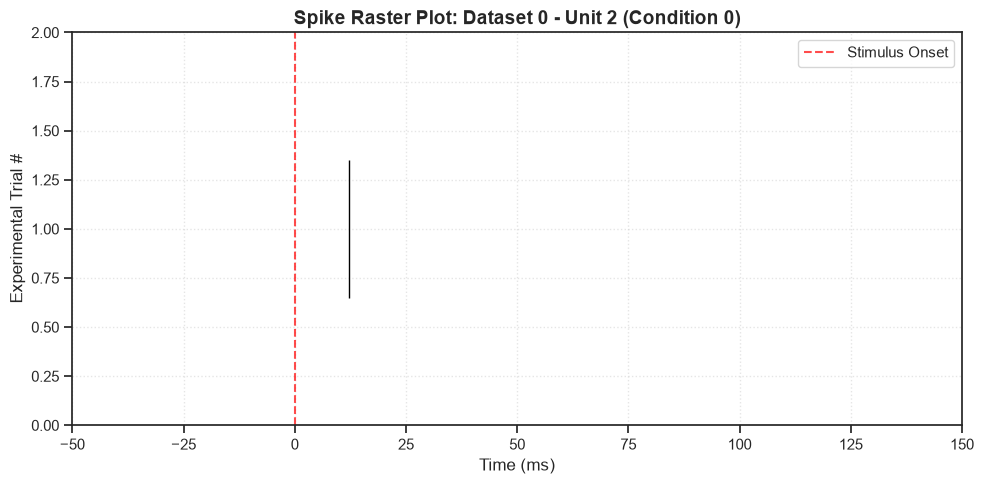

In [30]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Fetch data loader wrapper safely from notebook memory
data_loaders_list = PIPELINE_DATA.get("data_loaders")
if data_loaders_list is None:
    raise ValueError("Error: PIPELINE_DATA['data_loaders'] is empty.")

# 2. Extract Dataset 0 from the list container object
target_dataset_idx = 0
data_loaders = data_loaders_list[target_dataset_idx]

target_unit_idx = 1       # Index 1 targets the second recording unit (Unit 2)
target_condition_idx = 0  # Index 0 targets the baseline condition profile

try:
    # Safely navigate down the nested structure
    all_trains = data_loaders.all_cut_out_spike_trains
    unit_data = all_trains[target_unit_idx]
    unit_spike_trains = unit_data[target_condition_idx]
    
    print(f"--- Data Structural Inspection ---")
    print(f"Type of unit_spike_trains object: {type(unit_spike_trains)}")
    
    # Check if it's already an indexable collection of trials/sweeps
    if hasattr(unit_spike_trains, '__len__') and not isinstance(unit_spike_trains, (str, bytes)):
        total_trials = len(unit_spike_trains)
        # Ensure elements inside are formatted as arrays or lists of floats
        cleaned_spike_trains = [np.atleast_1d(trial) if hasattr(trial, '__len__') else np.array([trial]) for trial in unit_spike_trains]
    else:
        # If it's a scalar value or single float, wrap it into a valid 1-trial sequence structure
        print("[Structural Notice] Detected flat scalar array profile, formatting into a sequence...")
        cleaned_spike_trains = [np.atleast_1d(unit_spike_trains)]
        total_trials = 1

    print(f"Total active sweeps/trials prepared for plotting: {total_trials}")

    # 3. Create publication-quality raster using eventplot matrix mapping
    fig, ax = plt.subplots(figsize=(10, 5), dpi=100)
    
    # eventplot accepts an iterable list containing nested numpy arrays smoothly
    ax.eventplot(
        cleaned_spike_trains, 
        orientation='horizontal', 
        lineoffsets=np.arange(1, len(cleaned_spike_trains) + 1),
        linelengths=0.7, 
        colors='black', 
        linewidths=1.0
    )
    
    # 4. Standard Professional Visual Polish
    ax.set_title(f"Spike Raster Plot: Dataset {target_dataset_idx} - Unit 2 (Condition {target_condition_idx})", fontsize=14, fontweight='bold')
    ax.set_xlabel("Time (ms)", fontsize=12)
    ax.set_ylabel("Experimental Trial #", fontsize=12)
    
    # Standardize bounded window views (-50ms to 150ms as per Isbister 2021)
    ax.set_xlim([-50, 150])
    ax.set_ylim([0, len(cleaned_spike_trains) + 1])
    
    # Visual trigger alignment anchor line at time zero
    ax.axvline(x=0, color='red', linestyle='--', alpha=0.7, label='Stimulus Onset')
    ax.legend(loc='upper right')
    ax.grid(True, linestyle=':', alpha=0.5)
    
    plt.tight_layout()
    plt.show()

except Exception as core_err:
    print(f"\n[Execution Failure Log]: {core_err}")
    # Let's inspect data shapes directly without using the 'len' keyword on scalar properties
    print(f"-> Type of raw 'all_cut_out_spike_trains' container variable: {type(all_trains)}")
